### Specs:
- CPU: Intel Core Ultra 9 (x86-64)
- Numpy version: 2.5.4
- RAM: 16GB

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
print(np.__version__)

2.5.4



### 3.1 Multiplicative Model

The image is modelled as

$$I(x,y)=L(x,y)R(x,y)$$

where $L$ is illumination (mainly low frequencies) and $R$ represents reflectance (often high frequencies).

Taking logarithms:

$$\log I(x,y)=\log L(x,y)+\log R(x,y)$$

By linearity of the Fourier transform:

$$\mathcal{F}\{\log I\}=\mathcal{F}\{\log L\}+\mathcal{F}\{\log R\}$$

Thus, a frequency-domain high-frequency-emphasis filter can attenuate illumination variations while preserving reflectance details.

**Why log?**

Without taking the log first, multiplication and convolution are pairs hence a multiplication in the spatial domain would refer to a convolution in the frequency domain

$$\mathcal{F}\{LR\}=\hat L * \hat R$$
Filtering the log-magnitude spectrum instead does not solve this because
$$\log|\mathcal{F}\{I\}|\neq\mathcal{F}\{\log I\}$$

(3644, 3000)


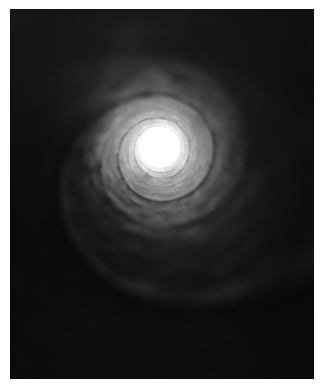

In [3]:
img = np.asarray(Image.open("A2\\Q3\\tunnel_image.jpg").convert("L"), dtype=np.float64) / 255.0
print(img.shape)
plt.imshow(img, cmap="gray", vmin=0, vmax=1)
plt.axis("off")
plt.show()

In [4]:

M, N = img.shape
u = np.arange(M) - M // 2
v = np.arange(N) - N // 2
D2 = u[:, None]**2 + v[None, :]**2

def homomorphic(img, gamma_L, gamma_H, D0, c=1):
    H = (gamma_H - gamma_L) * (1 - np.exp(-c * D2 / D0**2)) + gamma_L
    F = np.fft.fftshift(np.fft.fft2(np.log(img + 1e-6)))
    filtered = np.real(np.fft.ifft2(np.fft.ifftshift(H * F)))
    return np.exp(filtered)


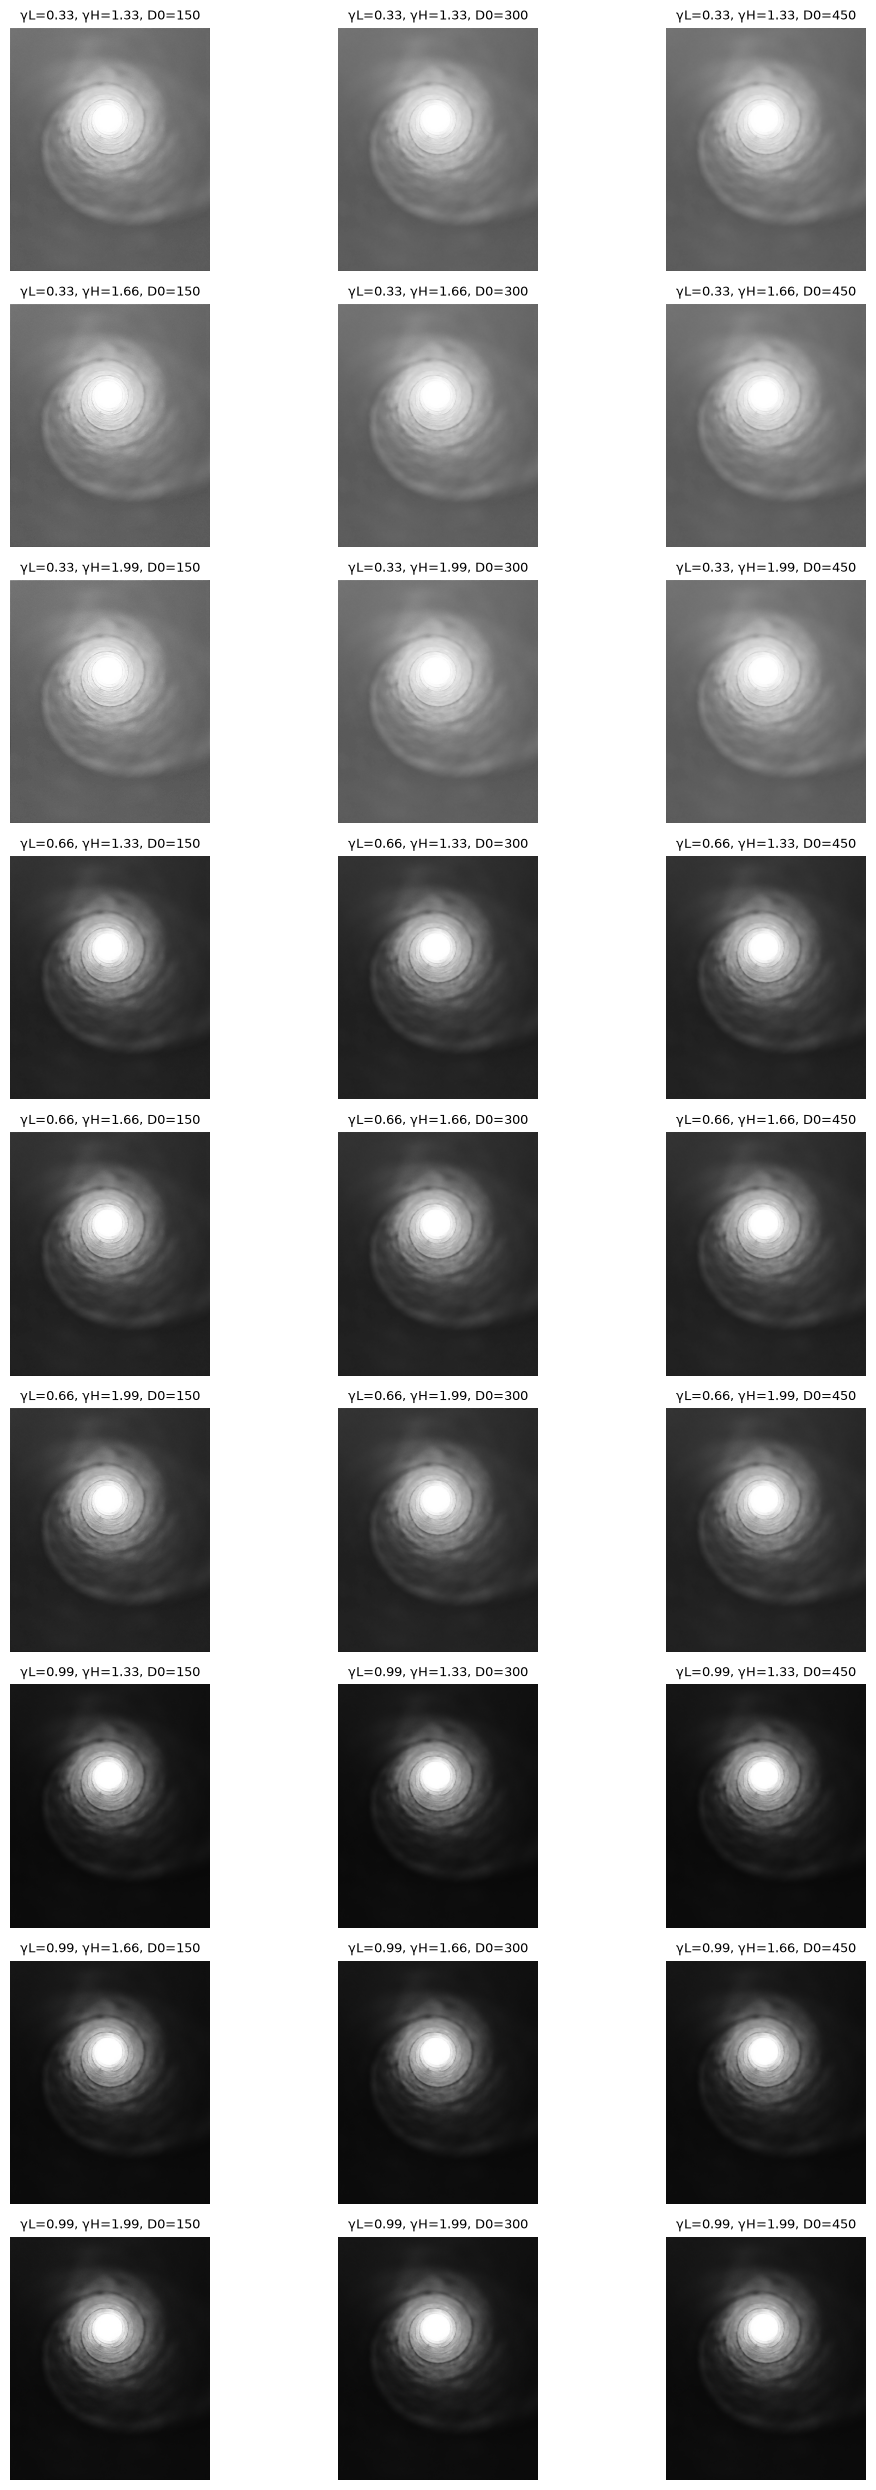

In [5]:

gamma_L_values = [0.33, 0.66, 0.99]
gamma_H_values = [1.33, 1.66, 1.99]
D0_values = [150, 300, 450]
fig, axes = plt.subplots(9, 3, figsize=(11, 25))

for i, gl in enumerate(gamma_L_values):
    for j, gh in enumerate(gamma_H_values):
        for k, d0 in enumerate(D0_values):
            ax = axes[i*3+j, k]
            out = homomorphic(img, gl, gh, d0)
            ax.imshow(np.clip(out, 0, 1), cmap="gray", vmin=0, vmax=1)
            ax.set_title(f"γL={gl}, γH={gh}, D0={d0}", fontsize=9)
            ax.axis("off")

plt.tight_layout()
plt.show()



### 3.2 Parameter Sweep and Observations

The parameter sweep uses:
- $\gamma_L = \{0.33,0.66,0.99\}$: as $\gamma_L \le 1$ I chose .33, 0.66, 0.99.
- $\gamma_H = \{1.33,1.66,1.99\}$: for any gamma greater than 2 I observed excessively amplify edges and noise hence chose 3 values between 1 and 2 -> 1.33, 1.66, 1.99
- $D_0 = \{150,300,450\}$: 5%, 10% and 15% of the smaller image dimension (3000 pixels).

**Observations:**
1. Decreasing $\gamma_L$ improves illumination uniformity, revealing more of the darker outer region.
2. Increasing $\gamma_H$ enhances texture and edges, but may exaggerate high-frequency details.
3. Increasing $D_0$ produces smoother results, with some loss of fine texture.

**Halo**
For $\gamma_H=1.99$ and $D_0=150$ settings we see a white thin line near the dark boundary near the center bright patch, these settings are potential halo cases, although clear artificial halos are not evident in any of the tested settings (testing takes long to run hence 3 per variable was chosen)

**Selected parameters:** $\gamma_L=0.66$, $\gamma_H=1.66$, $D_0=150$.
This combination provides a reasonable balance between illumination flattening and preservation of visible texture.

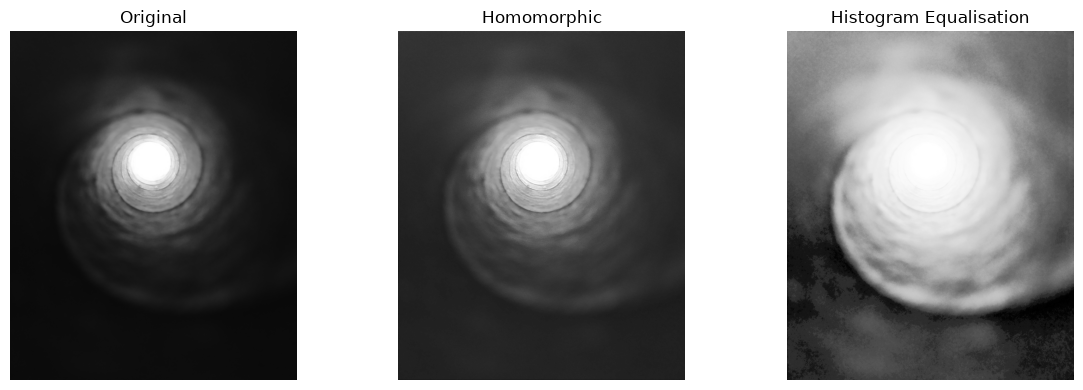

In [7]:
def equalize_hist(img):
    values = np.clip((img * 255).astype(np.uint8), 0, 255)
    hist = np.bincount(values.ravel(), minlength=256)
    cdf = np.cumsum(hist) / values.size
    return cdf[values]

he = equalize_hist(img)
hom = homomorphic(img, 0.66, 1.66, 150)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, image, title in zip(
    axes,
    [img, hom, he],
    ["Original", "Homomorphic", "Histogram Equalisation"]
):
    ax.imshow(np.clip(image, 0, 1), cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:
x1, x2 = 0, 1000
y1, y2 = 3000, 3500 

images = {
    "Original": img,
    "Homomorphic": hom,
    "Histogram Equalisation": he
}

for name, image in images.items():
    sigma = np.std(np.clip(image[y1:y2, x1:x2], 0, 1))
    print(f"{name}: {sigma:.4f}")


Original: 0.0046
Homomorphic: 0.0107
Histogram Equalisation: 0.0714



### Comparison with Global Histogram Equalisation
The local standard deviation in the selected shadow region increases from 0.0046 in the original image to 0.0107 after homomorphic filtering and 0.0714 after histogram equalisation.

Using the comparision image and the standard deviation of a dark patch (bottom left part of the orignal image) here are the observations:
- Homomorphic filtering improves shadow contrast while preserving the concentric textures and maintaining relatively uniform illumination.
- Histogram equalisation produces substantially greater local intensity variation, but this does not necessarily represent better detail recovery, since noise and unwanted intensity variations may also be amplified.

Visually, homomorphic filtering provides a more balanced enhancement of the darker tunnel regions while retaining the appearance of the bright central region. Histogram equalisation enhances the dark regions more aggressively but appears to overemphasise brightness and noise.

Hence, homomorphic filtering offers a better visual balance for this image, despite achieving a lower numerical local-contrast measure.